# 3. Customer Value and RFM Analysis
Profile purchase behavior, segment customers, estimate CLV, and identify high-value opportunities.

,customer_count,revenue,average_order_value,churn_rate
segment,,,,
Champions,493,645936.2060,95.061937,0.000000
At Risk,364,259260.7395,90.834372,0.315934
Loyal Customers,257,233994.7140,85.343039,0.000000
Lost Customers,827,197643.7230,92.768898,0.428053
Potential Loyalists,337,138442.5940,95.473249,0.000000
New Customers,58,1827.5165,31.508905,0.517241


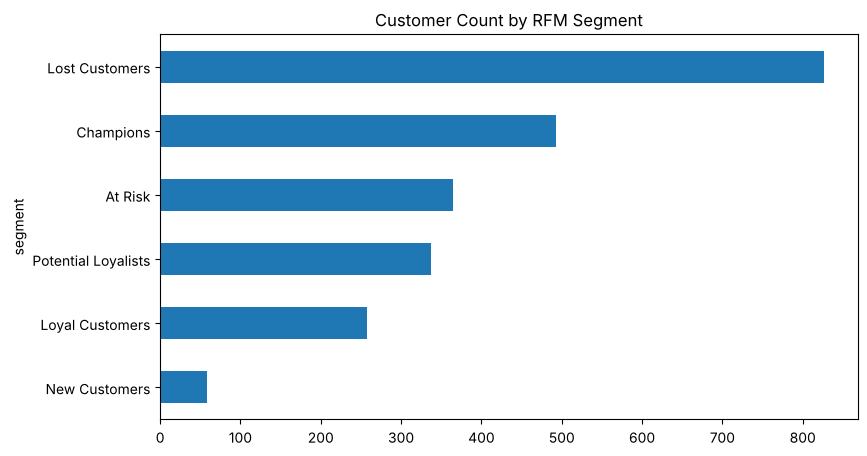

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
customers = pd.read_csv(ROOT / 'data' / 'processed' / 'customers_summary.csv')
summary = customers.groupby('segment').agg(customer_count=('customer_id','nunique'), revenue=('monetary','sum'), average_order_value=('average_order_value','mean'), churn_rate=('is_churned','mean')).sort_values('revenue', ascending=False)
display(summary)
summary.customer_count.sort_values().plot.barh(title='Customer Count by RFM Segment', figsize=(9,5)); plt.show()

In [2]:
customers['estimated_clv'] = customers.average_order_value * customers.frequency * 1.35
customers[['segment','estimated_clv','recency','frequency','monetary']].groupby('segment').mean().sort_values('estimated_clv', ascending=False)

,estimated_clv,recency,frequency,monetary
segment,,,,
Champions,1768.790828,7.610548,14.060852,1310.215428
Loyal Customers,1229.155112,23.766537,10.536965,910.485268
At Risk,961.543951,84.697802,7.873626,712.254779
Potential Loyalists,554.591994,9.130564,4.362018,410.808884
Lost Customers,322.634856,111.159613,2.640871,238.988782
New Customers,42.537022,151.017241,0.482759,31.508905
